In [86]:
import pandas as pd

In [87]:
df = pd.read_csv('retail.csv', encoding='cp1252')
df.head()

,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,State,Region,Category,Quantity,Sales
0,IN-2024-100001,02-01-2025,02-01-2025,Same Day,CUST-1507,Kavita Kumar,Corporate,Karnataka,South,Clothing,5,6615
1,IN-2025-100002,04-01-2025,08-01-2025,Second Class,CUST-2154,Divya Patel,Consumer,Rajasthan,North,Groceries,2,2166
2,IN-2023-100003,10-11-2024,13-11-2024,Second Class,CUST-2468,Rahul Gupta,Consumer,Telangana,South,Electronics,1,"28,109.50"
3,IN-2024-100004,26-07-2023,31-07-2023,Standard,CUST-2499,Divya Gupta,Home Office,Assam,East,Groceries,2,"1,022.00"
4,IN-2025-100005,13-02-2025,18-02-2025,Standard,CUST-2492,Rahul Chauhan,Consumer,West Bengal,East,Office Supplies,4,936


In [88]:
df.info

<bound method DataFrame.info of              Order ID  Order Date   Ship Date     Ship Mode Customer ID  \
0      IN-2024-100001  02-01-2025  02-01-2025      Same Day   CUST-1507   
1      IN-2025-100002  04-01-2025  08-01-2025  Second Class   CUST-2154   
2      IN-2023-100003  10-11-2024  13-11-2024  Second Class   CUST-2468   
3      IN-2024-100004  26-07-2023  31-07-2023      Standard   CUST-2499   
4      IN-2025-100005  13-02-2025  18-02-2025      Standard   CUST-2492   
...               ...         ...         ...           ...         ...   
10004  IN-2024-103220  31-01-2025  02-02-2025       Express   CUST-1682   
10005  IN-2024-108149  02-04-2023  09-04-2023      Standard   CUST-1314   
10006  IN-2025-105432  01-07-2023  08-07-2023      Standard   CUST-2736   
10007  IN-2024-106910  10-11-2025  11-11-2025       Express   CUST-1160   
10008  IN-2024-108905  06-03-2025  06-03-2025      Same Day   CUST-1709   

        Customer Name      Segment        State Region         Cate

In [89]:
df.describe(include='all')

,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,State,Region,Category,Quantity,Sales
count,10009,10009,10009,10009,10009,10009,10009,10009,10009,10009,10009.000000,10009
unique,9994,1096,1103,4,1793,395,3,14,4,5,NaN,5383
top,IN-2024-108905,03-09-2024,30-12-2024,Standard,CUST-1636,Kavita Pillai,Consumer,Gujarat,East,Groceries,NaN,720
freq,2,21,21,4993,14,80,6005,1275,2517,2558,NaN,25
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.057149,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.191216,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,NaN


In [90]:
df.isnull().sum()

Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
State            0
Region           0
Category         0
Quantity         0
Sales            0
dtype: int64

In [91]:
# Total missing values
df.isnull().sum().sum()

0

In [92]:
# Check unique values in every column
df.nunique()

Order ID         9994
Order Date       1096
Ship Date        1103
Ship Mode           4
Customer ID      1793
Customer Name     395
Segment             3
State              14
Region              4
Category            5
Quantity            5
Sales            5383
dtype: int64

In [93]:
df.columns = df.columns.str.lower()
df.columns = df.columns.str.replace(' ', '_')
df.columns

Index(['order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_id',
       'customer_name', 'segment', 'state', 'region', 'category', 'quantity',
       'sales'],
      dtype='object')

In [94]:
# Check the data types of each column
df.dtypes

order_id         object
order_date       object
ship_date        object
ship_mode        object
customer_id      object
customer_name    object
segment          object
state            object
region           object
category         object
quantity          int64
sales            object
dtype: object

In [95]:
df['order_date'] = pd.to_datetime(df['order_date'], dayfirst=True)
df['ship_date'] = pd.to_datetime(df['ship_date'], dayfirst=True)

df['sales'] = pd.to_numeric(df['sales'], errors='coerce')

In [96]:
df.dtypes

order_id                 object
order_date       datetime64[ns]
ship_date        datetime64[ns]
ship_mode                object
customer_id              object
customer_name            object
segment                  object
state                    object
region                   object
category                 object
quantity                  int64
sales                   float64
dtype: object

In [97]:
df.duplicated().sum()

15

In [98]:
df.drop_duplicates(inplace=True)

In [99]:
df.duplicated().sum()

0

In [100]:
df.describe()

,order_date,ship_date,quantity,sales
count,9994,9994,9994.000000,2549.000000
mean,2024-06-26 17:10:04.442665472,2024-06-30 07:19:45.111066624,2.056334,543.345822
min,2023-01-01 00:00:00,2023-01-01 00:00:00,1.000000,27.000000
25%,2023-09-21 00:00:00,2023-09-24 00:00:00,1.000000,320.000000
50%,2024-06-29 00:00:00,2024-07-03 00:00:00,2.000000,544.000000
75%,2025-03-28 00:00:00,2025-03-31 00:00:00,3.000000,770.000000
max,2025-12-31 00:00:00,2026-01-07 00:00:00,5.000000,6615.000000
std,NaN,NaN,1.190765,296.441860


In [101]:
df.describe(include='object')

,order_id,ship_mode,customer_id,customer_name,segment,state,region,category
count,9994,9994,9994,9994,9994,9994,9994,9994
unique,9994,4,1793,395,3,14,4,5
top,IN-2024-100001,Standard,CUST-1636,Kavita Pillai,Consumer,Gujarat,South,Groceries
freq,1,4988,14,80,5995,1274,2514,2558


In [102]:
import matplotlib.pyplot as plt

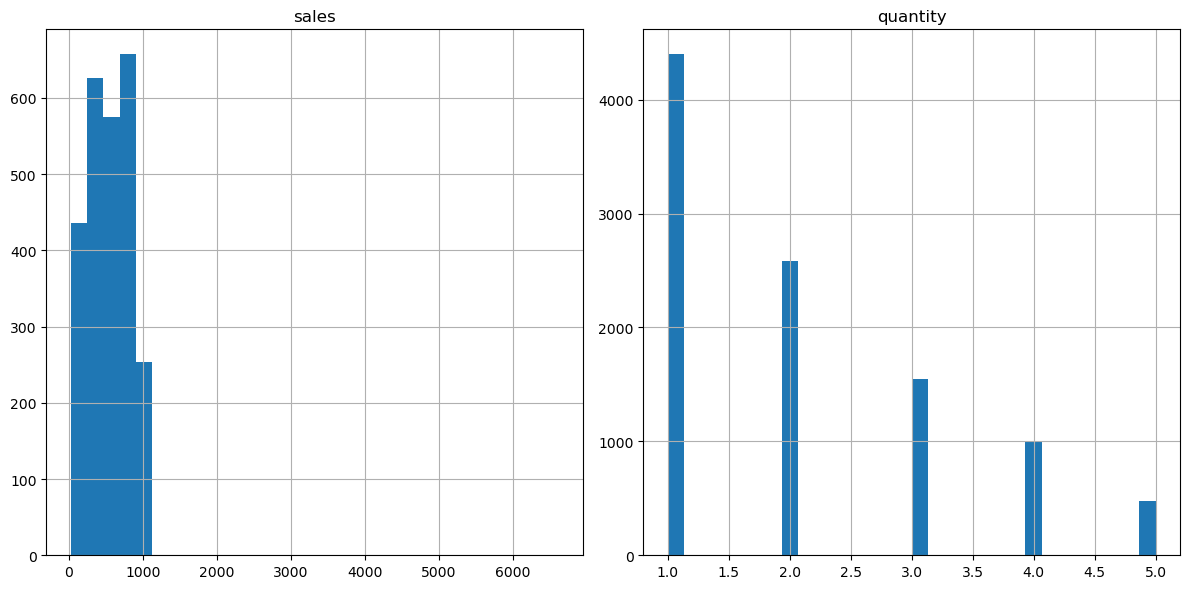

In [103]:
num_cols = ['sales', 'quantity']

df[num_cols].hist(
    figsize=(12, 6),
    bins=30
)

plt.tight_layout()
plt.show()

In [104]:
import seaborn as sns

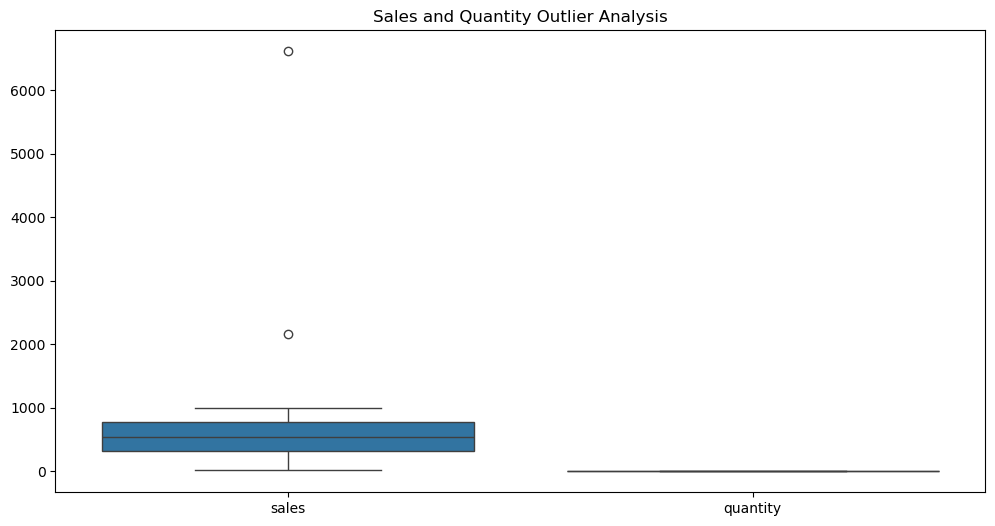

In [105]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[['sales', 'quantity']])
plt.title('Sales and Quantity Outlier Analysis')
plt.show()


In [106]:
# Check numeric columns for outliers using the IQR method
num_cols = df.select_dtypes(include='number').columns.tolist()
for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f'{col}: {count} outliers')


quantity: 0 outliers
sales: 2 outliers


### Analysis of Sales by Category

category
Groceries          792500.5
Office Supplies    363350.5
Clothing           212380.0
Electronics          9406.5
Furniture            7351.0
Name: sales, dtype: float64


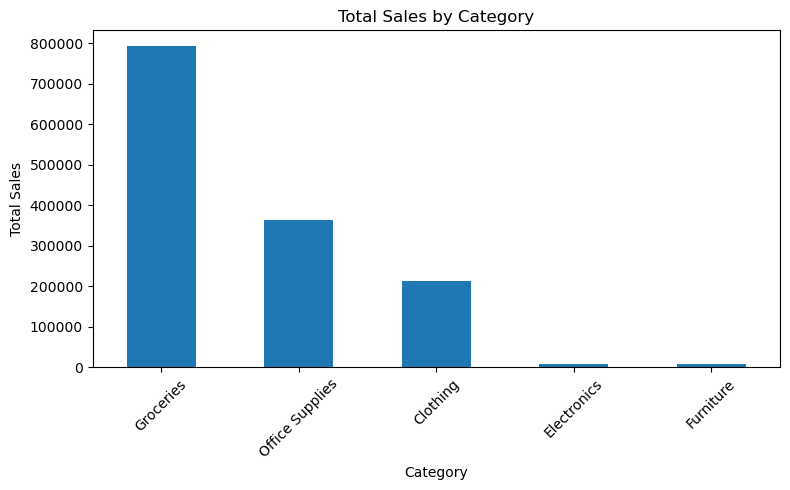

In [107]:
category_sales = df.groupby('category')['sales'].sum().sort_values(ascending=False)
print(category_sales)
category_sales.plot(kind='bar', figsize=(8, 5))
plt.title('Total Sales by Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


region
South    366463.5
West     355914.5
East     345343.5
North    317267.0
Name: sales, dtype: float64


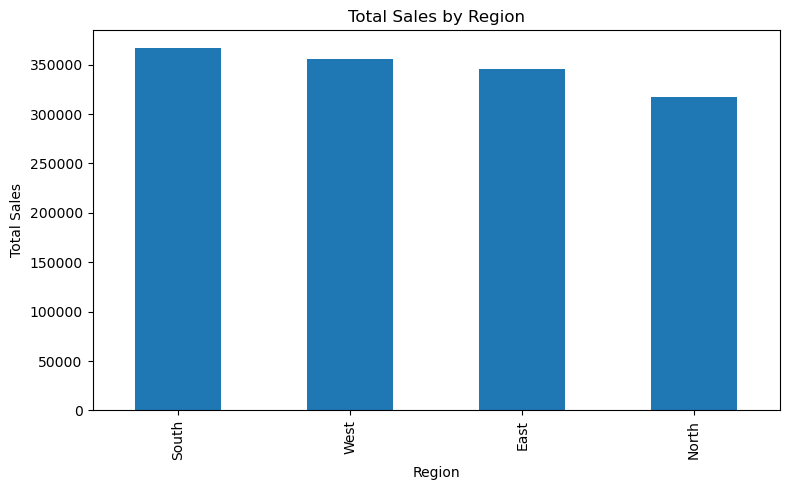

In [108]:
region_sales = df.groupby('region')['sales'].sum().sort_values(ascending=False)
print(region_sales)
region_sales.plot(kind='bar', figsize=(8, 5))
plt.title('Total Sales by Region')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.show()


segment
Consumer       844778.0
Corporate      335595.5
Home Office    204615.0
Name: sales, dtype: float64


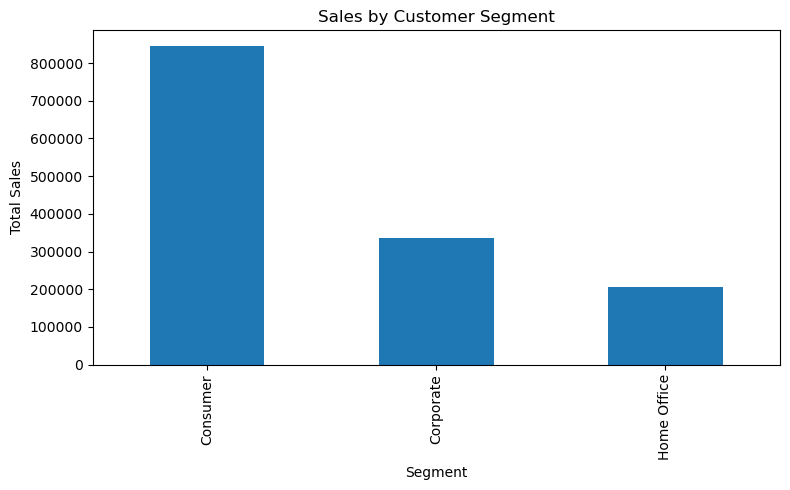

In [109]:
segment_sales = df.groupby('segment')['sales'].sum().sort_values(ascending=False)
print(segment_sales)
segment_sales.plot(kind='bar', figsize=(8, 5))
plt.title('Sales by Customer Segment')
plt.xlabel('Segment')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.show()


### Sales vs Quantity


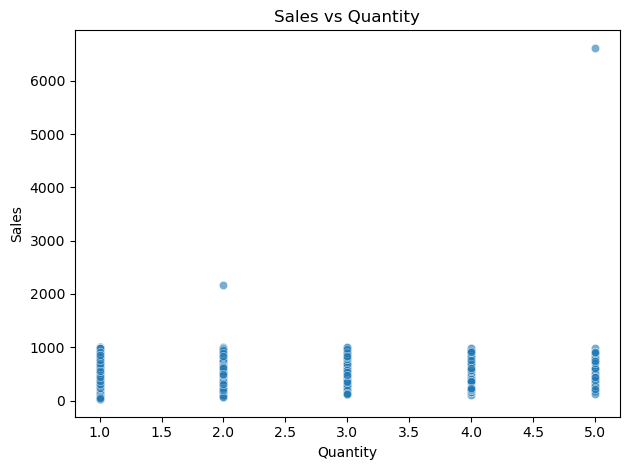

In [110]:
sns.scatterplot(data=df, x='quantity', y='sales', alpha=0.6)
plt.title('Sales vs Quantity')
plt.xlabel('Quantity')
plt.ylabel('Sales')
plt.tight_layout()
plt.show()


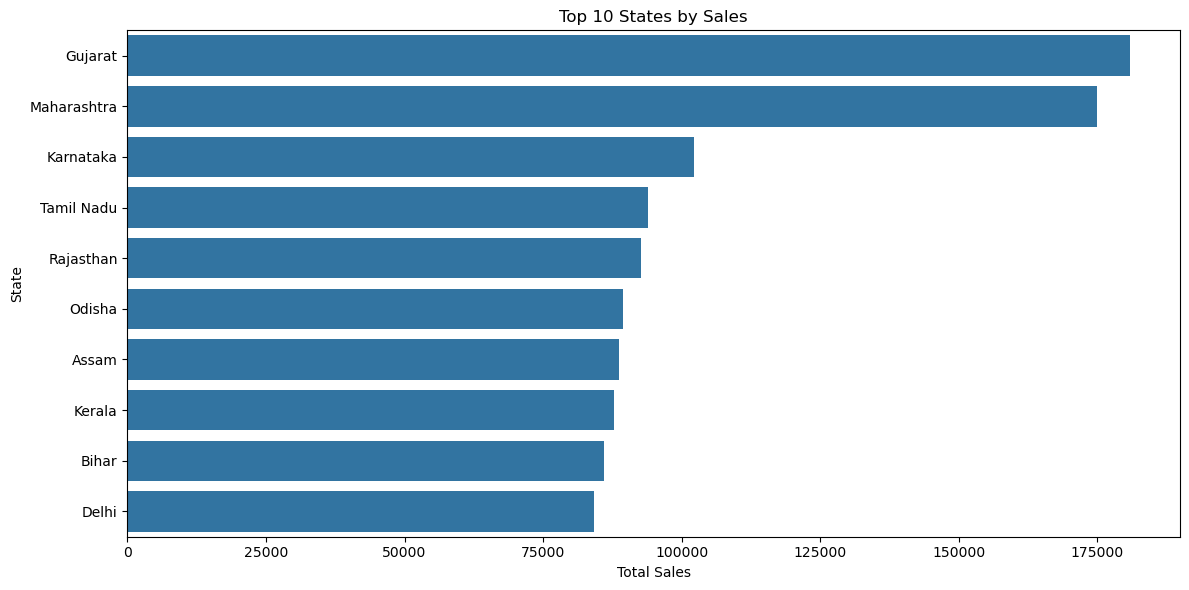

In [111]:
state_sales = df.groupby('state')['sales'].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(12, 6))
sns.barplot(x=state_sales.values, y=state_sales.index)
plt.title('Top 10 States by Sales')
plt.xlabel('Total Sales')
plt.ylabel('State')
plt.tight_layout()
plt.show()


### Monthly Sales

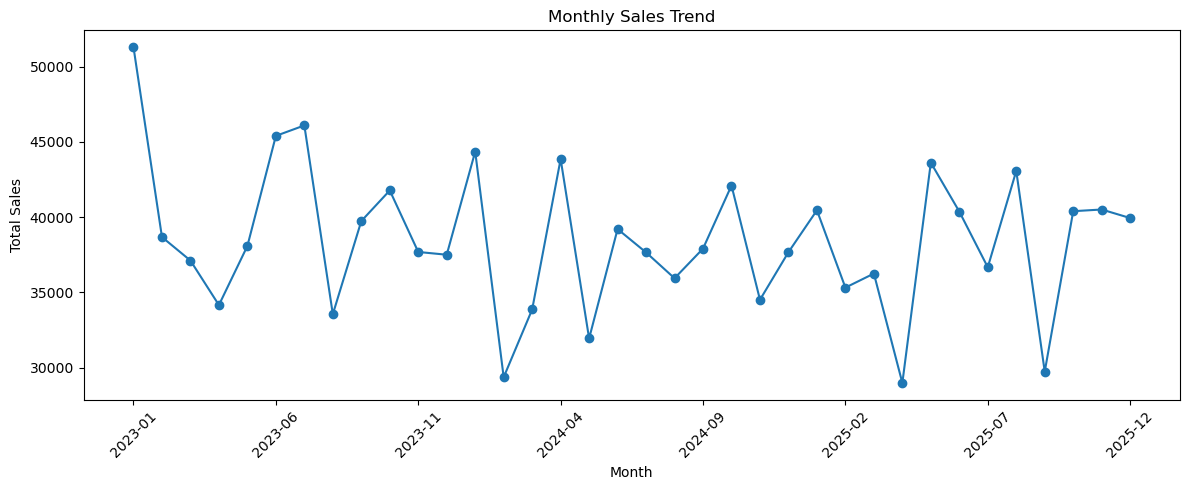

In [112]:
df['year_month'] = df['order_date'].dt.to_period('M')
monthly_sales = df.groupby('year_month')['sales'].sum()
monthly_sales.index = monthly_sales.index.astype(str)
monthly_sales.plot(figsize=(12, 5), marker='o')
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Yearly Sales

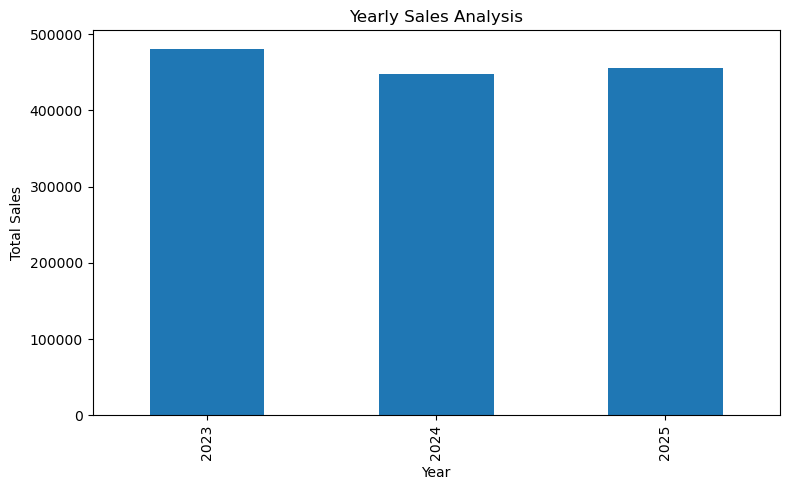

In [113]:
df['year'] = df['order_date'].dt.year
yearly_sales = df.groupby('year')['sales'].sum()
yearly_sales.plot(kind='bar', figsize=(8, 5))
plt.title('Yearly Sales Analysis')
plt.xlabel('Year')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.show()


### Top Customers by Sales


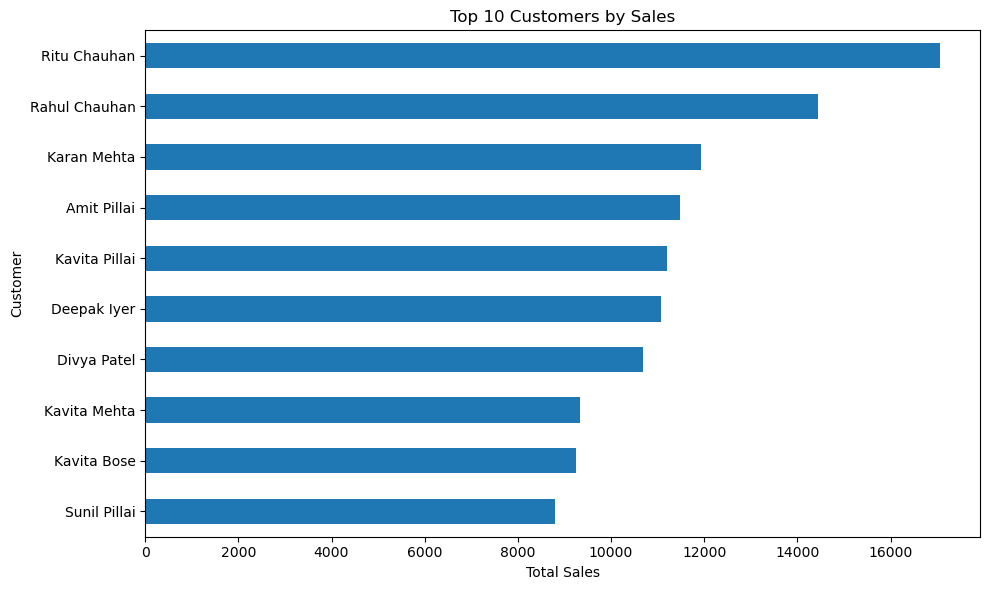

In [114]:
top_customers = df.groupby('customer_name')['sales'].sum().nlargest(10)
top_customers.plot(kind='barh', figsize=(10, 6))
plt.title('Top 10 Customers by Sales')
plt.xlabel('Total Sales')
plt.ylabel('Customer')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


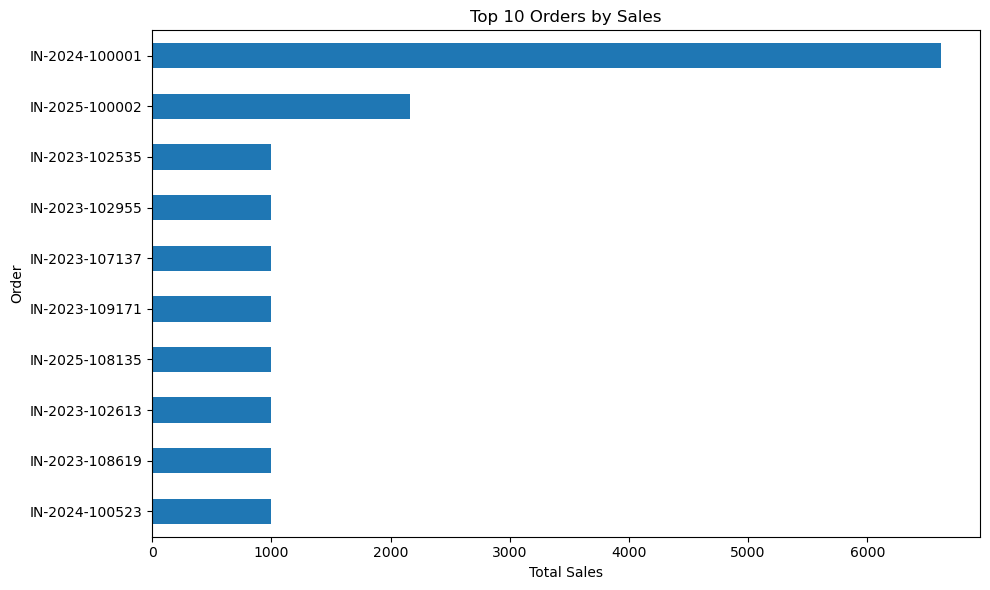

In [115]:
top_orders = df.groupby('order_id')['sales'].sum().nlargest(10)
top_orders.plot(kind='barh', figsize=(10, 6))
plt.title('Top 10 Orders by Sales')
plt.xlabel('Total Sales')
plt.ylabel('Order')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


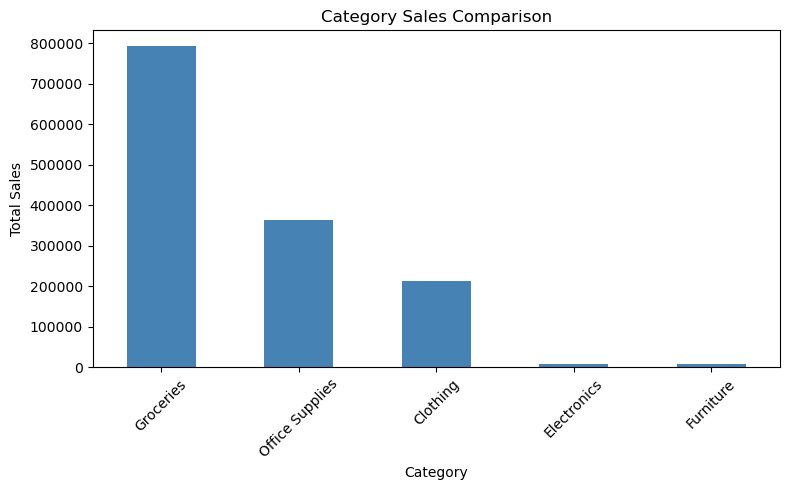

In [116]:
category_sales.plot(kind='bar', figsize=(8, 5), color='steelblue')
plt.title('Category Sales Comparison')
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


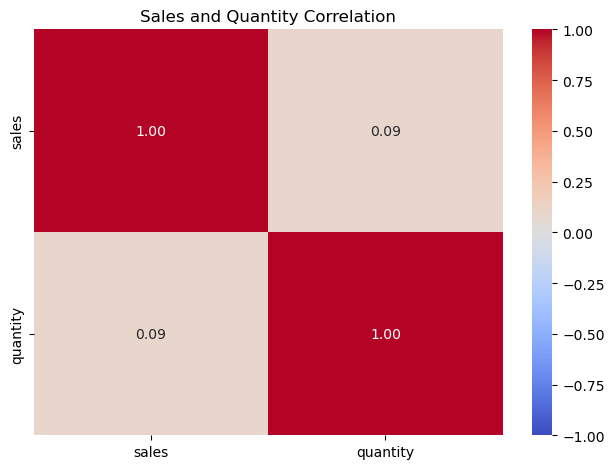

In [117]:
sns.heatmap(df[['sales', 'quantity']].corr(), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Sales and Quantity Correlation')
plt.tight_layout()
plt.show()


### Summary

In [118]:
print('========== RETAIL SALES INTELLIGENCE ==========')
print('Total Sales:', round(df['sales'].sum(), 2))
print('Total Orders:', df['order_id'].nunique())
print('Total Customers:', df['customer_id'].nunique())
print('Average Sales:', round(df['sales'].mean(), 2))
print('Average Quantity per Record:', round(df['quantity'].mean(), 2))
print('Best Selling Category:', df.groupby('category')['sales'].sum().idxmax())
print('Top Region by Sales:', df.groupby('region')['sales'].sum().idxmax())
print('Top Selling State:', df.groupby('state')['sales'].sum().idxmax())
print('Top Customer by Sales:', df.groupby('customer_name')['sales'].sum().idxmax())


========== RETAIL SALES INTELLIGENCE ==========
Total Sales: 1384988.5
Total Orders: 9994
Total Customers: 1793
Average Sales: 543.35
Average Quantity per Record: 2.06
Best Selling Category: Groceries
Top Region by Sales: South
Top Selling State: Gujarat
Top Customer by Sales: Ritu Chauhan


In [119]:
df.to_csv('retail_sales_cleaned.csv', index=False)
print('Cleaned data saved to retail_sales_cleaned.csv')


Cleaned data saved to retail_sales_cleaned.csv
